# 经典时序模型的滚动回测

在模拟月度序列上对比季节性朴素法、ETS 和 SARIMAX。固定 12 个月季节周期，
每个预测起点只用已有数据重新拟合，随后一次预测未来六个月。
所有模型使用相同的起点和预测期。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX

rng = np.random.default_rng(86)
t = np.arange(132)
noise = rng.normal(0, 2.0, len(t))
for i in range(1, len(noise)):
    noise[i] += 0.45 * noise[i - 1]

period, horizon = 12, 6
dates = pd.date_range("2014-01-01", periods=len(t), freq="MS")
series = pd.Series(35 + 0.22 * t + 5 * np.sin(2 * np.pi * t / period) + noise, index=dates)

records = []
for origin in range(72, len(series) - horizon + 1, 6):
    train = series.iloc[:origin]
    held_out = series.iloc[origin:origin + horizon]
    ets = ETSModel(train, error="add", trend="add", seasonal="add", seasonal_periods=period)
    sarimax = SARIMAX(train, order=(1, 0, 0), seasonal_order=(0, 1, 0, period), trend="c")
    forecasts = {
        "Seasonal naive": np.resize(train.iloc[-period:].to_numpy(), horizon),
        "ETS": ets.fit(disp=False).forecast(horizon).to_numpy(),
        "SARIMAX": sarimax.fit(disp=False).forecast(horizon).to_numpy(),
    }
    for name, predictions in forecasts.items():
        for step, (date, actual, predicted) in enumerate(
            zip(held_out.index, held_out, predictions), start=1
        ):
            records.append((date, name, step, actual, predicted))

scores = pd.DataFrame(records, columns=["date", "model", "step", "actual", "forecast"])
scores["abs_error"] = (scores["forecast"] - scores["actual"]).abs()
scores["squared_error"] = scores["abs_error"] ** 2
summary = scores.groupby("model").agg(MAE=("abs_error", "mean"), MSE=("squared_error", "mean"))
summary["RMSE"] = np.sqrt(summary.pop("MSE"))
summary.round(3)

,MAE,RMSE
model,,
ETS,1.902,2.273
SARIMAX,2.498,3.166
Seasonal naive,3.375,4.276


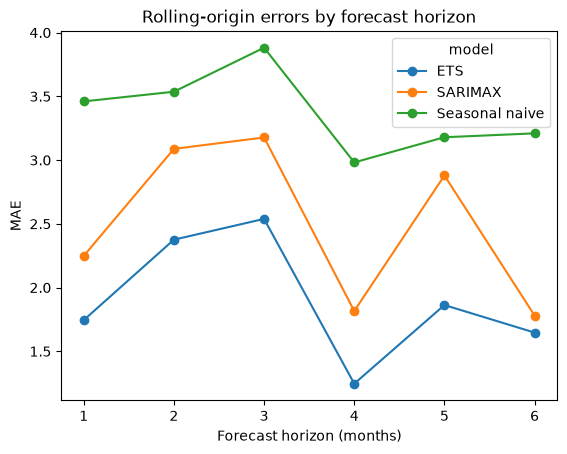

In [2]:
by_step = scores.pivot_table(index="step", columns="model", values="abs_error")
ax = by_step.plot(marker="o", ylabel="MAE", xlabel="Forecast horizon (months)")
ax.set_title("Rolling-origin errors by forecast horizon")
plt.show()

## 应用到赛题数据

先根据日期检查采样频率、缺期和季节周期。样本较短时可用最近值作为第二个朴素基线。
有真正可提前取得的外部变量时，可以把它交给 SARIMAX；每折都按其预测时点限制可用信息。